# 18 · Detrending and fitting together: a Gaussian process with the transit

**Level:** intermediate · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb), [06](06_marginal_transit_model.ipynb) helps · **Run time:** ~2 min (most of it the download, the first compilation and the spline filter)

**Covers:** `MarginalTransitModel(..., gp=pizzetti.GP())`, a light curve that is not detrended, `gp_predict`, reading the GP parameters, a comparison with no detrending and with two filters, when a GP helps and when to be careful

Tutorial 11 removed the stellar variability first and fitted the transits afterwards. That is two steps: the filter does not know the transit, and the fit does not know that the trend was uncertain. With `gp=` both happen in one step. The noise model holds an additive Gaussian process (GP), its parameters are sampled with the transit, and the limb darkening and the baseline are still integrated out exactly.

We fit K2-33 b, a Neptune-sized planet of a star only 5 to 10 million years old ([David et al. 2016](https://doi.org/10.1038/nature18293)). Its transits are 2.5 ppt deep and 4 hours long. The young, spotted star changes its brightness by up to 20 ppt per day, so the transits sit on steep, curved trends, some of them on a turnover. Among the 100 light curves of the paper's benchmark it is the one where the trend changes most during the transit (apart from AU Mic and DS Tuc A, see the end).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # lightkurve warns about an optional package
warnings.filterwarnings("ignore", category=RuntimeWarning)  # overflows while the optimiser probes extreme geometries
import math
import time as clock
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import corner
from scipy.ndimage import median_filter
from wotan import flatten, transit_mask
import pizzetti

## Step 1: download the light curve

The EVEREST pipeline has removed K2's pointing systematics, but it keeps the star's own variability. One point every 30 minutes, for about 80 days. Period, mid-transit time and duration come from the NASA Exoplanet Archive. A few dozen cadences have a flux near or below zero: artefacts, which we drop before anything else.

2601 cadences, 66 with flux below 0.9 dropped


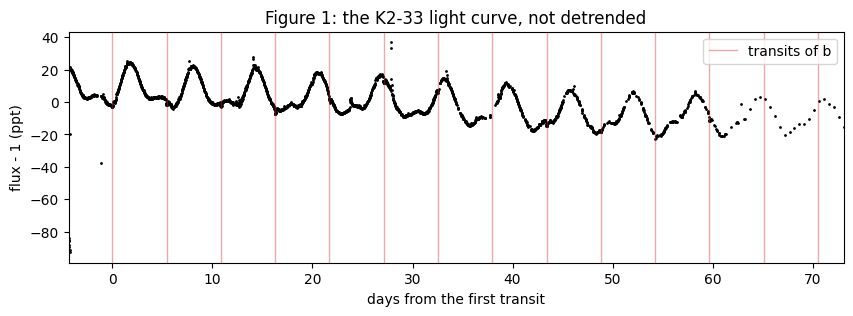

In [2]:
search = lk.search_lightcurve("K2-33", mission="K2", author="EVEREST", exptime=1800)
lc = search.download().remove_nans().normalize()
bjd = lc.time.jd
flux = np.asarray(lc.flux.value, dtype=float)
bad = flux < 0.9
print(f"{len(flux)} cadences, {bad.sum()} with flux below 0.9 dropped")
bjd, flux = bjd[~bad], flux[~bad]

per, tc, t14 = 5.424865, 2456898.69288, 0.17        # days, BJD, days (T14 = 4.1 h)
exposure = np.median(np.diff(bjd))                   # days

def phase_of(t, period, epoch):
    return (t - epoch + 0.5 * period) % period - 0.5 * period

plt.figure(figsize=(10, 3))
plt.plot(bjd - tc, 1e3 * (flux - 1), "k.", ms=2)
for e in range(-1, 16):
    plt.axvline(e * per, color="C3", lw=1, alpha=0.4, label="transits of b" if e == 0 else None)
plt.xlim(bjd[0] - tc, bjd[-1] - tc)
plt.xlabel("days from the first transit"); plt.ylabel("flux - 1 (ppt)"); plt.legend(loc="upper right")
plt.title("Figure 1: the K2-33 light curve, not detrended");

## Step 2: keep windows around the transits, in time order

We take ±3 durations around each transit: enough out-of-transit data for the GP to learn the trend from. Two things differ from tutorial 11:

- **The light curve is not folded.** A GP correlates neighbours in time, so `t` stays in ascending order and the transits keep their own epochs. `gp=` raises an error if `t` is not ascending.
- **Nothing is detrended.**

Outliers are removed per window, against a running median after dividing by a rough transit. Flux is deliberately not compared between windows: there the trend would look like an outlier. We keep the windows with data on both sides of the transit.

In [3]:
def start_params():
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = 0.0, per, 0.0432, 10.4
    p.inc = math.degrees(math.acos(0.16 / 10.4))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [0.4, 0.25]
    return p

K = 15                                                    # sub-exposures for the 30-minute cadence
t_all = bjd - tc
phase = phase_of(t_all, per, 0.0)
epoch = np.round(t_all / per).astype(int)
near = np.abs(phase) < 3 * t14
t, y, ep = t_all[near], flux[near], epoch[near]

# white noise per point, from point-to-point differences: insensitive to the trend
sigma = 1.4826 * np.median(np.abs(np.diff(y[np.abs(phase[near]) > 0.6 * t14]))) / math.sqrt(2)
p0 = start_params()
rough = pizzetti.TransitModel(p0, t, supersample_factor=K, exp_time=exposure, offsets="midpoint").light_curve(p0)
keep = np.ones(len(t), bool)
for e in np.unique(ep):
    m = ep == e
    r = y[m] / rough[m]
    keep[m] = np.abs(r - median_filter(r, size=5, mode="nearest")) < 5 * sigma
for e in np.unique(ep):                                   # data on both sides of the transit
    m = keep & (ep == e)
    h = t[m] - e * per
    if np.sum(h < -0.6 * t14) < 4 or np.sum(h > 0.6 * t14) < 4 or np.sum(np.abs(h) < 0.5 * t14) < 2:
        keep[ep == e] = False
t, y, ep = t[keep], y[keep], ep[keep]
epochs = np.unique(ep)
print(f"{len(t)} points in {len(epochs)} windows, white noise {sigma * 1e6:.0f} ppm per point")

416 points in 10 windows, white noise 341 ppm per point


## Step 3: what if we do not detrend?

As a baseline, a plain `fit()` of these points with white noise. Each window has its own level and slope, but the model has one flat baseline `f0`.

In [4]:
free = ("t0", "rp", "a", "b")
kw = dict(free=free, bounds={"t0": (-0.5 * t14, 0.5 * t14), "rp": (1e-4, 0.5)},
          supersample_factor=K, exp_time=exposure, offsets="midpoint")

raw = pizzetti.MarginalTransitModel(start_params(), t, y, sigma, **kw).fit(seed=1)
print(raw.summary())

              median     -1sigma     +1sigma
t0        0.03628869     0.00123     0.00126
rp        0.06005502      0.0121       0.018
a           6.158744        2.41        1.82
b          0.6545807       0.503       0.293
q1         0.8022875        0.62       0.139
q2         0.9122355       0.438      0.0693
f0          1.000387     1.9e-05    1.94e-05


The mid-transit time `t0` is off by about 50 minutes, and the posterior of `rp` has two peaks: one flat baseline cannot describe these windows.

## Step 4: the fit with a GP

One more argument. `pizzetti.GP()` adds three sampled parameters:

| label | meaning | default prior (log-uniform) |
|---|---|---|
| `ln_gp_amp` | rms of the GP, in flux units | 0.02 × median `yerr` to 0.2 × median flux |
| `ln_gp_tau` | its time scale in days | median cadence to 180 T14 |
| `ln_err_scale` | factor on `yerr` for the white noise | 1/3 to 3 |

`yerr` only has to be right within those limits. Every call that works without a GP works here: `fit()`, `FitResult`, `corner`, `EnsembleSampler`.

In [5]:
model = pizzetti.MarginalTransitModel(start_params(), t, y, sigma, gp=pizzetti.GP(), **kw)
start = clock.perf_counter()
result = model.fit(seed=1)
print(f"{clock.perf_counter() - start:.1f} s, {result.diagnostics['n_eval']} likelihood evaluations, "
      f"k-hat {result.diagnostics['khat']:.2f}, ESS {result.diagnostics['ess']:.0f}, is_ok = {result.diagnostics['is_ok']}\n")
print(result.summary())

2.4 s, 14346 likelihood evaluations, k-hat 0.13, ESS 2185, is_ok = True

                     median     -1sigma     +1sigma
t0             0.0003500786     0.00119     0.00126
rp               0.04944042     0.00413     0.00489
a                  7.369872        1.59        2.04
b                 0.6735758       0.384       0.141
ln_gp_amp         -4.608012       0.169       0.206
ln_gp_tau        -0.2056632       0.149       0.156
ln_err_scale     -0.1216443      0.0418      0.0406
q1                 0.561271       0.214       0.272
q2                0.5105049       0.269       0.294
f0                0.9987261     0.00267     0.00266


## Step 5: look at the GP

`model.gp_predict(row)` gives the GP at the data times for one row of `result.samples`, given that row's transit. So `y - gp_predict(row)` is the detrended light curve. With `t=` it also gives the GP at any other times, which we use to draw smooth curves between the data points. We evaluate it for 100 posterior draws. The dashed line is the trend under the transit, and its band shows how well it is known there.

residual rms 267 ppm, fitted white noise 302 ppm


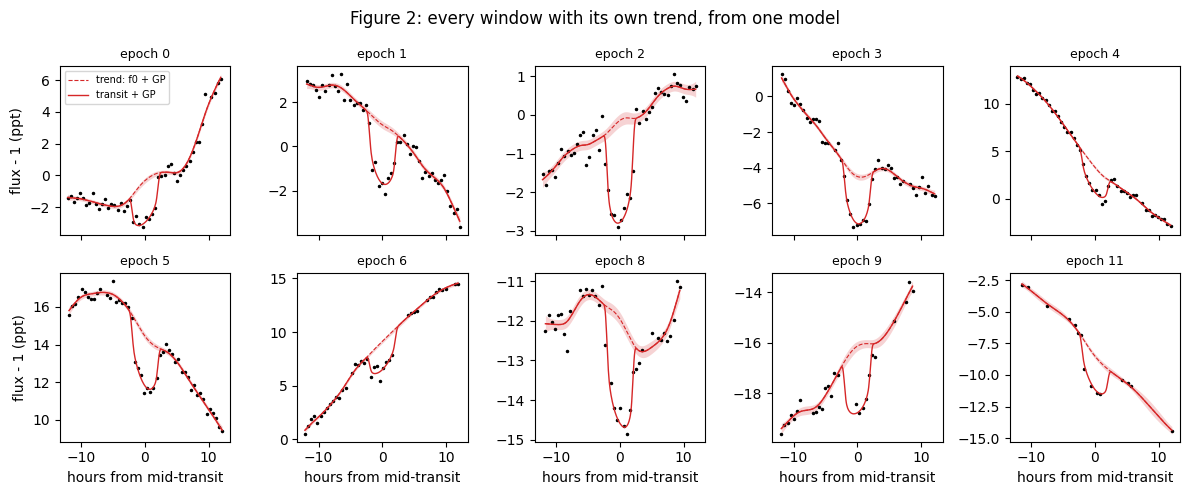

In [6]:
labels = list(result.labels)
rng = np.random.default_rng(2)
rows = result.samples[rng.choice(len(result.samples), 100, replace=False)]

def transit_of(row, times):
    """The transit of one row of samples, including the baseline f0."""
    c = dict(zip(labels, row))
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = c["t0"], per, c["rp"], c["a"]
    p.inc = math.degrees(math.acos(c["b"] / c["a"]))
    sq = math.sqrt(c["q1"])
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [2 * sq * c["q2"], sq * (1 - 2 * c["q2"])]
    tm = pizzetti.TransitModel(p, times, supersample_factor=K, exp_time=exposure, offsets="midpoint")
    return c["f0"] * tm.light_curve(p)

# the model at the data times, for the residuals
full = np.mean([transit_of(r, t) + model.gp_predict(r) for r in rows], axis=0)
f0s = rows[:, labels.index("f0")]
curves = {}                                               # per window: fine times, model, trend and its sd
for e in epochs:
    m = ep == e
    fine = np.linspace(t[m][0], t[m][-1], 300)
    pred = [model.gp_predict(r, t=fine, return_var=True) for r in rows]
    gp_f = np.array([p[0] for p in pred])
    base = gp_f + f0s[:, None]           # the constant part of the GP is degenerate with f0, so we plot their sum
    base_sd = np.sqrt(base.var(axis=0) + np.mean([p[1] for p in pred], axis=0))
    model_f = (np.array([transit_of(r, fine) for r in rows]) + gp_f).mean(axis=0)
    curves[e] = (fine, model_f, base.mean(axis=0), base_sd)

fig, axs = plt.subplots(2, 5, figsize=(12, 5), sharex=True)
for ax, e in zip(axs.flat, epochs):
    m = ep == e
    fine, model_f, base, base_sd = curves[e]
    hf = 24 * (fine - e * per)
    ax.plot(24 * (t[m] - e * per), 1e3 * (y[m] - 1), "k.", ms=3)
    ax.fill_between(hf, 1e3 * (base - base_sd - 1), 1e3 * (base + base_sd - 1), color="C3", alpha=0.2, lw=0)
    ax.plot(hf, 1e3 * (base - 1), "C3--", lw=0.8, label="trend: f0 + GP")
    ax.plot(hf, 1e3 * (model_f - 1), "C3", lw=1, label="transit + GP")
    ax.set_title(f"epoch {e}", fontsize=9)
for ax in axs[1]:
    ax.set_xlabel("hours from mid-transit")
for ax in axs[:, 0]:
    ax.set_ylabel("flux - 1 (ppt)")
axs[0, 0].legend(loc="best", fontsize=7)
fig.suptitle("Figure 2: every window with its own trend, from one model")
fig.tight_layout()
s = math.exp(np.median(result.samples[:, labels.index("ln_err_scale")]))
print(f"residual rms {(y - full).std() * 1e6:.0f} ppm, fitted white noise {sigma * s * 1e6:.0f} ppm")

## Step 6: what a filter would do

For comparison, the two-step route of tutorial 11: a filter with the transits masked, then a plain `fit()` of ±1.5 durations around each transit. The filter has to pass through every window as the GP does. We try three, all from wotan:

- **biweight, 2 days:** the rule of the paper's benchmark, a window of max(2 d, 3 T14). Here that is 2 days.
- **biweight, 3 T14 = 0.5 days:** short enough for this star.
- **Huber spline, knots every 4 T14:** a robust spline (needs scikit-learn), which fits a smooth function instead of sliding a window.

biweight, 2 d        misses the flux next to the transits by up to 3.3 ppt
biweight, 3 T14      misses the flux next to the transits by up to 1.4 ppt
Huber spline, 4 T14  misses the flux next to the transits by up to 0.4 ppt


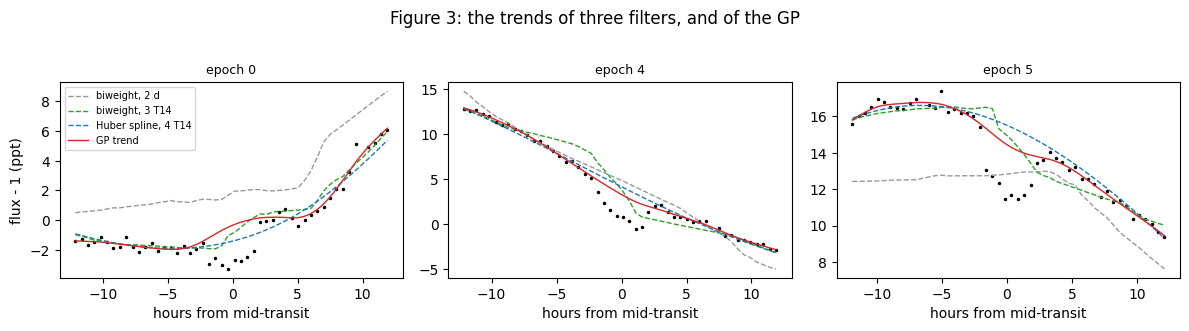

In [7]:
mask = transit_mask(time=t_all, period=per, duration=1.1 * t14 + exposure, T0=0.0)
filters = {"biweight, 2 d": dict(method="biweight", window_length=2.0),
           "biweight, 3 T14": dict(method="biweight", window_length=3 * t14),
           "Huber spline, 4 T14": dict(method="hspline", window_length=4 * t14)}
trends = {name: flatten(t_all, flux, mask=mask, return_trend=True, **f)[1] for name, f in filters.items()}

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, e in zip(axs, (0, 4, 5)):
    m = (epoch == e) & (np.abs(phase) < 3 * t14)
    ax.plot(24 * phase[m], 1e3 * (flux[m] - 1), "k.", ms=3)
    for (name, tr), c in zip(trends.items(), ("0.6", "C2", "C0")):
        ax.plot(24 * phase[m], 1e3 * (tr[m] - 1), color=c, lw=1, ls="--", label=name)
    ax.plot(24 * (curves[e][0] - e * per), 1e3 * (curves[e][2] - 1), "C3", lw=1, label="GP trend")
    ax.set_title(f"epoch {e}", fontsize=9); ax.set_xlabel("hours from mid-transit")
axs[0].set_ylabel("flux - 1 (ppt)"); axs[0].legend(fontsize=7)
fig.suptitle("Figure 3: the trends of three filters, and of the GP", y=1.02)
fig.tight_layout()

oot_near = (np.abs(phase) > 0.6 * t14) & (np.abs(phase) < 1.5 * t14)
for name, tr in trends.items():
    off = [np.median(flux[(epoch == e) & oot_near] - tr[(epoch == e) & oot_near]) for e in epochs]
    print(f"{name:20s} misses the flux next to the transits by up to {1e3 * np.max(np.abs(off)):.1f} ppt")

The 2-day biweight is too long: it averages over a trend that curves within the window, and it misses the flux next to the transits by a few ppt. A shorter window follows the trend outside the transits, but the masked transit leaves the window one-sided next to each transit, and on this steep slope its trend jumps at the edges of the mask. The Huber spline bridges the masked transits smoothly. Now the fits of the filtered data, with the white noise from the scatter outside the transits:

In [8]:
def filtered_fit(trend):
    flat = flux / trend
    win = (np.abs(phase) < 1.5 * t14) & np.isin(epoch, epochs) & np.isfinite(flat)
    tf, yf, pf = t_all[win], flat[win], phase[win]
    oot = np.abs(pf) > 0.5 * t14 + exposure
    sig = 1.4826 * np.median(np.abs(yf[oot] - np.median(yf[oot])))
    o = np.argsort(pf)                                    # clip on the fold: the levels now agree
    keep = np.ones(len(yf), bool)
    keep[o] = np.abs(yf[o] - median_filter(yf[o], size=3, mode="nearest")) < 5 * sig
    res = pizzetti.MarginalTransitModel(start_params(), tf[keep], yf[keep], sig, **kw).fit(seed=1)
    return res, sig

filtered = {}
for name in ("biweight, 2 d", "Huber spline, 4 T14"):
    filtered[name], sig = filtered_fit(trends[name])
    print(f"{name}: white noise {sig * 1e6:.0f} ppm, k-hat {filtered[name].diagnostics['khat']:.2f}")
    print(filtered[name].summary(), "\n")

biweight, 2 d: white noise 1272 ppm, k-hat 0.15
              median     -1sigma     +1sigma
t0     -0.0007982365     0.00467     0.00432
rp        0.04762464     0.00417      0.0527
a           7.722768         4.3         1.7
b          0.5716575       0.378       0.431
q1         0.5678274       0.344       0.294
q2         0.5295258       0.335       0.316
f0         0.9999143    0.000121     0.00012 



Huber spline, 4 T14: white noise 466 ppm, k-hat 0.38
              median     -1sigma     +1sigma
t0       0.001765124     0.00154     0.00137
rp        0.05224992     0.00544     0.00612
a           6.639791        1.75        2.43
b          0.7240563       0.441       0.141
q1         0.6374753       0.277       0.241
q2         0.4915432       0.277       0.304
f0         0.9999798    4.21e-05    4.51e-05 



The filters leave residuals of 0.5 to 1.3 ppt per point, which the fit then takes as white noise. The GP fits white noise of 0.3 ppt and puts the rest into the trend. Now the posteriors of the transit parameters side by side, using the exact weighted draws:

no detrending          Rp/R* = 0.0601 +0.0180 -0.0121   t0 = +52.3 ± 1.8 min
biweight, 2 d          Rp/R* = 0.0476 +0.0538 -0.0042   t0 =  -1.1 ± 6.5 min
Huber spline, 4 T14    Rp/R* = 0.0522 +0.0061 -0.0055   t0 =  +2.5 ± 2.1 min
GP with the transit    Rp/R* = 0.0493 +0.0049 -0.0041   t0 =  +0.5 ± 1.8 min


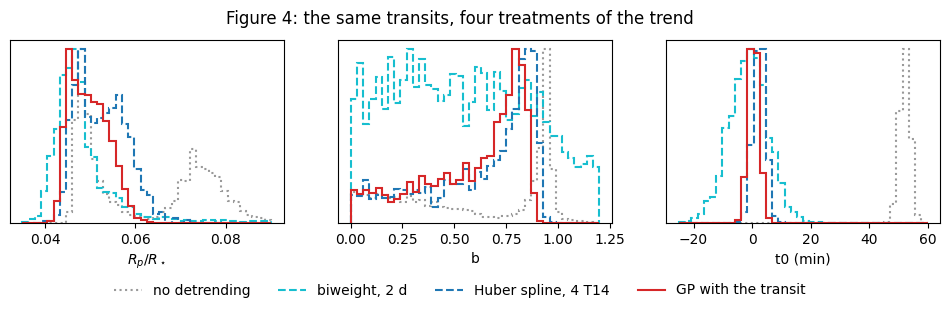

In [9]:
def quantiles(res_, name):
    j = list(res_.labels).index(name)
    o = np.argsort(res_.weighted_samples[:, j]); cw = np.cumsum(res_.weights[o])
    return np.interp([0.16, 0.5, 0.84], cw / cw[-1], res_.weighted_samples[o, j])

runs = [("no detrending", raw, "0.6", ":"), ("biweight, 2 d", filtered["biweight, 2 d"], "C9", "--"),
        ("Huber spline, 4 T14", filtered["Huber spline, 4 T14"], "C0", "--"), ("GP with the transit", result, "C3", "-")]
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for lab, res_, col, ls in runs:
    for ax, (n, rng_) in zip(axs, (("rp", (0.035, 0.09)), ("b", (0, 1.2)), ("t0", (-25, 60)))):
        x = res_.weighted_samples[:, list(res_.labels).index(n)]
        x = 1440 * x if n == "t0" else x
        h, edges = np.histogram(x, bins=40, range=rng_, weights=res_.weights)
        ax.stairs(h / h.max(), edges, color=col, ls=ls, lw=1.5, label=lab)
    q = quantiles(res_, "rp"); qt = 1440 * quantiles(res_, "t0")
    print(f"{lab:22s} Rp/R* = {q[1]:.4f} +{q[2] - q[1]:.4f} -{q[1] - q[0]:.4f}   t0 = {qt[1]:+5.1f} ± {(qt[2] - qt[0]) / 2:.1f} min")
for ax, xl in zip(axs, (r"$R_p/R_\star$", "b", "t0 (min)")):
    ax.set_xlabel(xl); ax.set_yticks([])
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02), frameon=False)
fig.subplots_adjust(bottom=0.27)
fig.suptitle("Figure 4: the same transits, four treatments of the trend");

Without detrending, the posterior is in the wrong place. The 2-day biweight gives a wide posterior with a long tail to large `rp`, because its residual trends count as noise. The Huber spline and the GP agree, and the GP gives the narrowest posterior of `rp`. It needed no choice of a filter or a window, and its error bars already include the uncertainty of the trend under each transit.

## Step 7: the planet

The corner plot of the planet's parameters shows the GP fit and the Huber spline fit together.

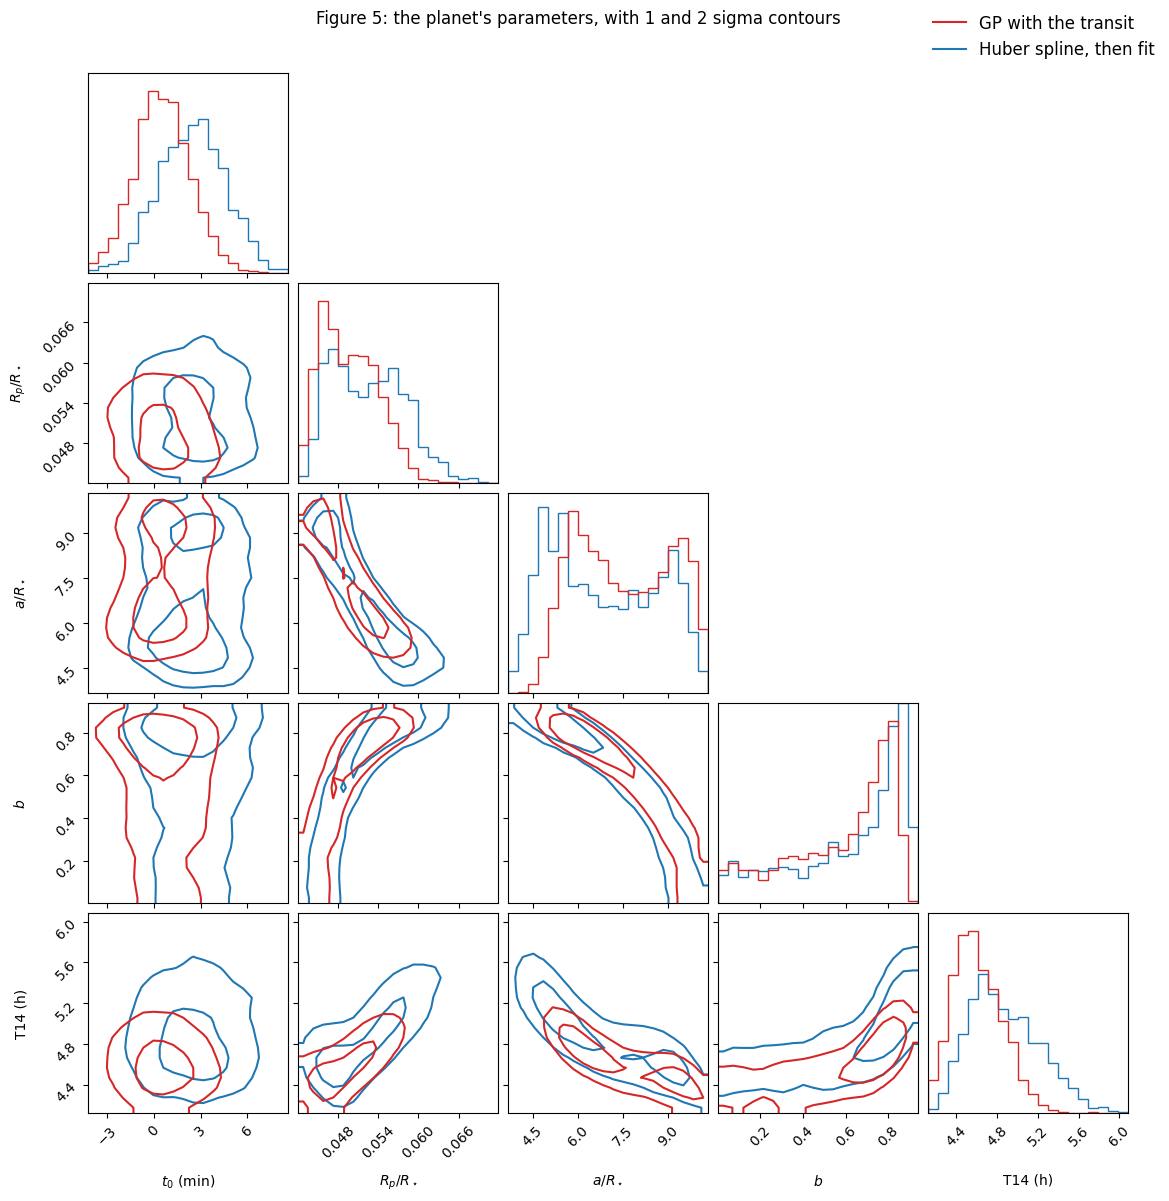

In [10]:
def t14_hours(c):
    return 24 * per / np.pi * np.arcsin(np.sqrt(np.clip((1 + c["rp"]) ** 2 - c["b"] ** 2, 0, None)) / np.sqrt(c["a"] ** 2 - c["b"] ** 2))

def planet_columns(res_):
    c = {n: res_.weighted_samples[:, j] for j, n in enumerate(res_.labels)}
    return np.column_stack([24 * 60 * c["t0"], c["rp"], c["a"], c["b"], t14_hours(c)])

spline = filtered["Huber spline, 4 T14"]
names_p = [r"$t_0$ (min)", r"$R_p/R_\star$", r"$a/R_\star$", r"$b$", "T14 (h)"]
Xg, Xs = planet_columns(result), planet_columns(spline)
def weighted_range(x, w):                             # 0.3 to 99.7 per cent of the weighted draws
    o = np.argsort(x); cw = np.cumsum(w[o])
    return np.interp([0.003, 0.997], cw / cw[-1], x[o])
lims = [[weighted_range(X[:, j], r.weights) for X, r in ((Xg, result), (Xs, spline))] for j in range(5)]
ranges = [(min(a[0], b[0]), max(a[1], b[1])) for a, b in lims]
fig = corner.corner(Xs, weights=spline.weights, labels=names_p, range=ranges, color="C0", smooth=1.0, hist_kwargs=dict(density=True),
                    plot_datapoints=False, plot_density=False, no_fill_contours=True, levels=(0.39, 0.86))
corner.corner(Xg, weights=result.weights, range=ranges, color="C3", smooth=1.0, hist_kwargs=dict(density=True), fig=fig,
              plot_datapoints=False, plot_density=False, no_fill_contours=True, levels=(0.39, 0.86))
fig.legend(handles=[plt.Line2D([], [], color="C3", label="GP with the transit"), plt.Line2D([], [], color="C0", label="Huber spline, then fit")],
           loc="upper right", frameon=False, fontsize=12)
fig.suptitle("Figure 5: the planet's parameters, with 1 and 2 sigma contours", y=1.02);

## Step 8: the GP parameters

The hyperparameters are worth reading. Here the corner plot shows the two parameters of the GP, the white noise, and `Rp/R*`.

amplitude 10.0 ppt (8.4 to 12.3), time scale 0.81 d (0.70 to 0.95) = 4.8 T14, white noise 0.89 x yerr


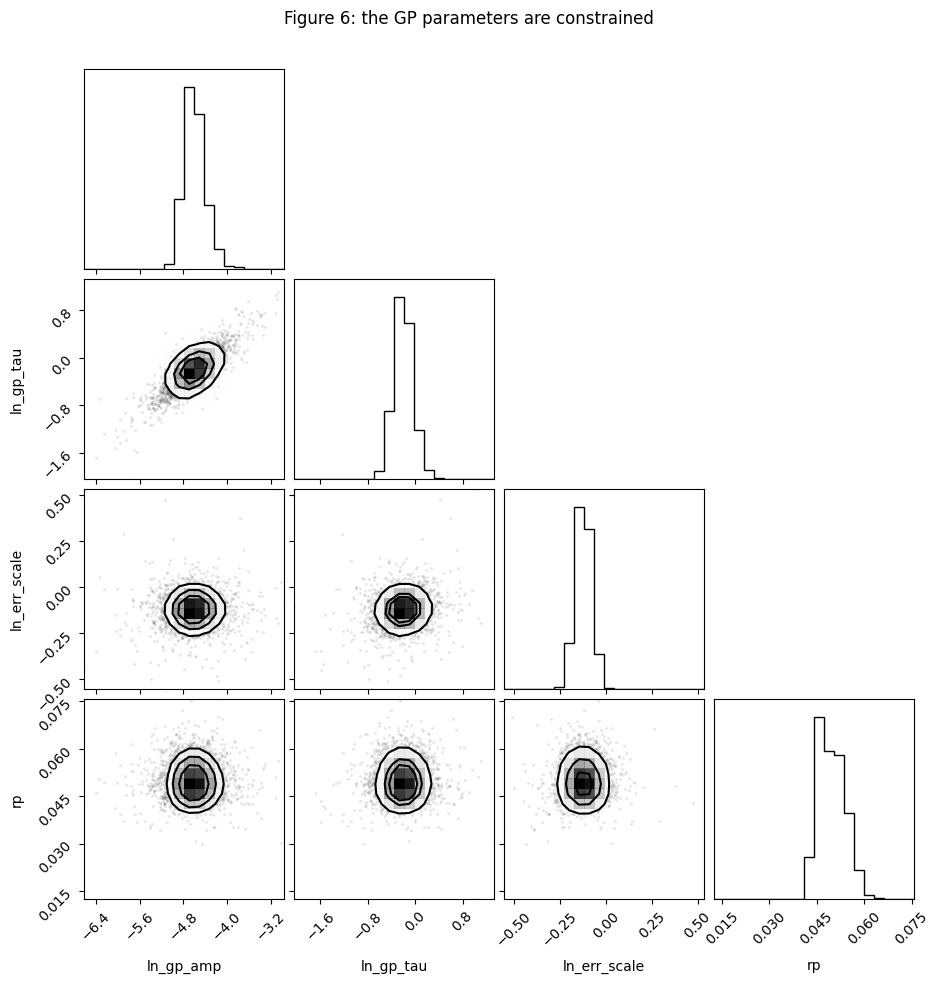

In [11]:
idx = [labels.index(n) for n in ("ln_gp_amp", "ln_gp_tau", "ln_err_scale", "rp")]
fig = corner.corner(result.weighted_samples[:, idx], weights=result.weights, labels=[labels[i] for i in idx], smooth=1.0)
fig.suptitle("Figure 6: the GP parameters are constrained", y=1.02);
q = np.percentile(result.samples[:, idx[:3]], [16, 50, 84], axis=0)
print(f"amplitude {1e3 * math.exp(q[1, 0]):.1f} ppt ({1e3 * math.exp(q[0, 0]):.1f} to {1e3 * math.exp(q[2, 0]):.1f}), "
      f"time scale {math.exp(q[1, 1]):.2f} d ({math.exp(q[0, 1]):.2f} to {math.exp(q[2, 1]):.2f}) = {math.exp(q[1, 1]) / t14:.1f} T14, "
      f"white noise {math.exp(q[1, 2]):.2f} x yerr")

The time scale (about 0.8 days, 5 T14) is shorter than a window (1 day), so the data fix the amplitude and the time scale separately, and both posteriors are compact. This is different from a star whose trend is much slower than the windows: there the GP is a smooth curve whose constant part is degenerate with `f0`, the data fix only amplitude / time scale, and the two form a ridge that runs into the prior bounds. That is harmless for the transit, but the bounds are then part of the model. The white noise comes out a little below the point-to-point estimate we passed as `yerr`, within the allowed factor of 3.

## When is this worth it?

**Use it when** the trend is hard to filter: its time scale is comparable to the window a filter would need, the transits are long, or you do not want to choose a filter and a window. On K2-33 the paper's default filter window was too long and a shorter one jumped at the mask edges; it took a third filter to follow the trend. On 14 raw Kepler, K2 and TESS light curves, 10 agreed with biweight fits within 0.4 σ. Simulated trends near the transit's time scale gave conservative error bars where two-step fits were overconfident (rms z of R_p/R_★ of 0.55, against 1.6–1.8, in 8 noise realisations).

**Be careful when** the GP's time scale comes close to T14 and its amplitude far exceeds the depth. On very active stars (AU Mic b, DS Tuc A b: amplitude 6–8 × the depth, time scale ≈ T14) the GP gave R_p/R_★ 2–3 σ from biweight fits. The fit converges, but a single-time-scale GP may then absorb part of the transit, and it is not yet established which is right. K2-33 lies between these regimes (amplitude about 4 × the depth, time scale 5 T14). Compare with a filter, and test with injected transits.

**Good to know:**
- The GP is *additive*. For trends of a few per cent the depth changes by a similar fraction of itself.
- Flares and other outliers are not modelled: clip them first.
- Cost: every evaluation also whitens the data at O(N), so a fit takes several times longer than the two-step fit (figures in the [documentation](https://pizzetti.readthedocs.io/en/latest/marginal.html#correlated-noise-a-gaussian-process)).
- Scope: quadratic law, primary transits, `ld_prior` "physical" or a callable. Other laws raise `NotImplementedError`.

**Options:**
```python
pizzetti.GP(tau=0.5)                       # a number holds a parameter fixed: a known time scale, in days
pizzetti.GP(err_scale=1.0)                 # trust yerr
pizzetti.GP(amp=1e-2, tau=0.8, err_scale=0.9)     # all three fixed: much faster, ignores their uncertainty
pizzetti.GP(amp=(1e-4, 1e-1), tau=(0.1, 5.0))     # tuple: bounds of the log-uniform prior

def log_prior(d):                          # any prior, also on the GP's sampled logarithms, by label
    return -0.5 * ((d["ln_gp_tau"] - np.log(1.0)) / 0.5) ** 2
```

## What you learned

- `gp=pizzetti.GP()` fits the correlated noise together with the transit; limb darkening and baseline remain integrated out, and `fit()`, `FitResult` and `EnsembleSampler` work as before.
- The light curve must stay in time order, with enough data around each transit to show the trend.
- `gp_predict` gives the trend and the detrended light curve for any posterior draw.
- A filter needs a method and a window that suit the star; the GP learns its time scale from the data.
- `ln_gp_amp` and `ln_gp_tau` show what the data constrain. A trend slower than the windows fixes only their ratio.

**Next:** [the theory and the cost](https://pizzetti.readthedocs.io/en/latest/marginal.html#correlated-noise-a-gaussian-process), [tutorial 15](15_when_the_profile_is_not_enough.ipynb) for reading `diagnostics`.